In [38]:
import os
import re
from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ee
import geemap



#####################################
#    SET ALL PARAMETERS #############
#####################################

PROJECT_DIR = "projects/ee-tymc5571-cbi-module/assets"
GEE_PROJECT = "ee-tymc5571-cbi-module"

In [3]:
ee.Authenticate(
    auth_mode='notebook',
    scopes=[
        'https://www.googleapis.com/auth/earthengine',
        'https://www.googleapis.com/auth/devstorage.read_write',
        'https://www.googleapis.com/auth/drive'
    ]
)
ee.Initialize(project=GEE_PROJECT)


Successfully saved authorization token.


In [ ]:
def list_assets(parent: str) -> list[str]:
    """Recursively list asset IDs under an Earth Engine folder/collection."""
    assets = []
    def _list(parent_id):
        response = ee.data.listAssets({'parent': parent_id})
        for item in response.get('assets', []):
            asset_id = item.get('name')
            asset_type = item.get('type')
            if asset_type in ('FOLDER', 'IMAGE_COLLECTION'):
                _list(asset_id)
            else:
                assets.append(asset_id)
    _list(parent)
    return assets

# Gather bc-cbi image assets and wrap as ImageCollections
dir_assets = list_assets(PROJECT_DIR)

fired_assets = [a for a in dir_assets if "bccbi_firedv2" in a]
print("Fired available:", len(fired_assets))
fired = ee.ImageCollection.fromImages([ee.Image(a) for a in fired_assets])

welty_assets = [a for a in dir_assets if "bccbi_welty" in a]
print("Welty available:", len(welty_assets))
welty = ee.ImageCollection.fromImages([ee.Image(a) for a in welty_assets])

wumi_c_assets = [a for a in dir_assets if "bccbi_wumi_west_circles" in a]
print("WUMI West Circles available:", len(wumi_c_assets))
wumi_c = ee.ImageCollection.fromImages([ee.Image(a) for a in wumi_c_assets])

wumi_nc_assets = [a for a in dir_assets if "bccbi_wumi_west_nocircles" in a]
print("WUMI West No Circles available:", len(wumi_nc_assets))
wumi_nc = ee.ImageCollection.fromImages([ee.Image(a) for a in wumi_nc_assets])

conservative_forest = ee.Image("projects/ee-tymc5571-cbi-module/assets/conservative_forest_1985_2024")

Fired available: 25
Welty available: 36
WUMI West Circles available: 40
WUMI West No Circles available: 40


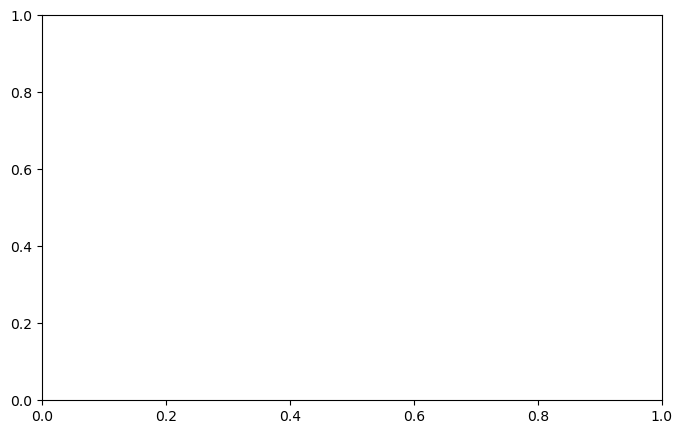

In [ ]:
# compare for 2006


def image_for_year(ic, year):
    return ee.Image(ic.filter(ee.Filter.eq("year", year)).first())

def hist_fixed(img, band, region=None, scale=30,
               min_val=0.0, max_val=3.0, bins=256,
               max_pixels=1e13, best_effort=True, tile_scale=4):
    img = ee.Image(img).select([band])
    if region is None:
        region = img.geometry()

    out = img.reduceRegion(
        reducer=ee.Reducer.fixedHistogram(min_val, max_val, bins),
        geometry=region,
        scale=scale,
        bestEffort=best_effort,
        maxPixels=max_pixels,
        tileScale=tile_scale
    )
    return out.get(band)

# ---- run ----
YEAR = 2006
BAND = "CBI_bc"
aoi = None

min_val, max_val, bins = 0.0, 3.0, 60
scale = 30

collections = {"fired": fired, "welty": welty, "wumi_c": wumi_c, "wumi_nc": wumi_nc}

# Store raw histogram output from GEE here
hists = {}  # name -> python list returned by getInfo()

for name, ic in collections.items():
    img = image_for_year(ic, YEAR)

    # Exclude masked pixels / NAs (only valid pixels remain)
    img = img.updateMask(img.select(BAND).mask())

    hist = ee.List(
        hist_fixed(
            img, BAND,
            region=aoi,
            scale=scale,
            min_val=min_val,
            max_val=max_val,
            bins=bins
        )
    ).getInfo()

    # hist is now a normal Python list (can be saved, reused, pickled, etc.)
    hists[name] = hist if hist else []


In [36]:
print(hists.keys())

for k, v in hists.items():
    print(k, len(v))

for k, v in hists.items():
    print(k, v[:-1])


dict_keys(['fired', 'welty', 'wumi_c', 'wumi_nc'])
fired 30
welty 30
wumi_c 30
wumi_nc 30
fired [[0, 3920886], [0.1, 751813], [0.2, 542181], [0.30000000000000004, 631458], [0.4, 734219], [0.5, 594643], [0.6000000000000001, 628448], [0.7000000000000001, 482610], [0.8, 637253], [0.9, 578488], [1, 741025], [1.1, 886165], [1.2000000000000002, 1468396], [1.3, 866056], [1.4000000000000001, 570376], [1.5, 904408], [1.6, 820228], [1.7000000000000002, 971320], [1.8, 781551], [1.9000000000000001, 746394], [2, 599160], [2.1, 488536], [2.2, 506627], [2.3000000000000003, 443094], [2.4000000000000004, 480875], [2.5, 491860], [2.6, 419171], [2.7, 393810], [2.8000000000000003, 377736]]
welty [[0, 4889888], [0.1, 825372], [0.2, 637212], [0.30000000000000004, 760765], [0.4, 881217], [0.5, 767097], [0.6000000000000001, 851243], [0.7000000000000001, 663774], [0.8, 873652], [0.9, 783669], [1, 968683], [1.1, 1161592], [1.2000000000000002, 1848131], [1.3, 1078035], [1.4000000000000001, 708802], [1.5, 1098921

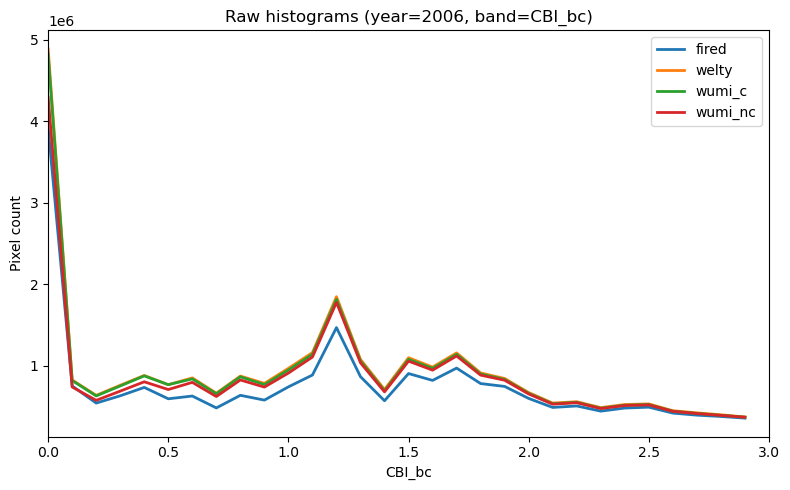

In [29]:
# ---- plot stored histograms ----
fig, ax = plt.subplots(figsize=(8, 5))
bin_width = (max_val - min_val) / bins

for name, hist in hists.items():
    if not hist:
        continue

    arr = np.array(hist, dtype=float)

    if arr.shape[1] == 2:
        # [x, count]
        x = arr[:, 0]
        counts = arr[:, 1]

    elif arr.shape[1] == 3:
        # [min, max, count] OR [start, width, count]
        a = arr[:, 0]
        b = arr[:, 1]
        counts = arr[:, 2]

        if np.all(b > a):
            x = (a + b) / 2.0
        else:
            x = a + b / 2.0

    else:
        raise ValueError(f"Unexpected histogram shape for {name}: {arr.shape}")

    ax.plot(
        x,
        counts,
        label=name,
        linewidth=2
    )

# Axis labels & limits
ax.set_title(f"Raw histograms (year={YEAR}, band={BAND})")
ax.set_xlabel(BAND)
ax.set_ylabel("Pixel count")
ax.set_xlim(min_val, max_val)

ax.legend()
fig.tight_layout()
plt.show()


In [30]:
import numpy as np

zero_bin_props = {}

for name, hist in hists.items():
    if not hist:
        zero_bin_props[name] = np.nan
        continue

    arr = np.array(hist, dtype=float)   # shape (n_bins, 2)
    bin_start = arr[:, 0]
    counts = arr[:, 1]

    total = counts.sum()
    if total == 0:
        zero_bin_props[name] = np.nan
        continue

    # robust float comparison in case bin_start is 0.0-ish
    zero_mask = np.isclose(bin_start, 0.0, atol=1e-12)

    zero_count = counts[zero_mask].sum()
    zero_bin_props[name] = zero_count / total

for k, v in zero_bin_props.items():
    print(f"{k}: {v:.6f}")


fired: 0.171846
welty: 0.176851
wumi_c: 0.176884
wumi_nc: 0.165428


In [ ]:
# RUN FOR 2001-2020

def hist_fixed(img, band, region=None, scale=30,
               min_val=0.0, max_val=3.0, bins=256,
               max_pixels=1e13, best_effort=True, tile_scale=4):
    img = ee.Image(img).select([band])
    if region is None:
        region = img.geometry()

    out = img.reduceRegion(
        reducer=ee.Reducer.fixedHistogram(min_val, max_val, bins),
        geometry=region,
        scale=scale,
        bestEffort=best_effort,
        maxPixels=max_pixels,
        tileScale=tile_scale
    )
    return out.get(band)

def get_hist_for_year(ic, year, band, region=None, scale=30,
                      min_val=0.0, max_val=3.0, bins=256,
                      max_pixels=1e13, best_effort=True, tile_scale=4):
    """
    Returns a Python list of histogram rows for (ic, year) or None if missing.
    Assumes year is stored as a property named 'year'.
    """
    img = ic.filter(ee.Filter.eq("year", year)).first()

    # Mask NAs for this band
    img = ee.Image(img).updateMask(ee.Image(img).select(band).mask())

    try:
        hist = ee.List(
            hist_fixed(
                img, band,
                region=region,
                scale=scale,
                min_val=min_val, max_val=max_val, bins=bins,
                max_pixels=max_pixels,
                best_effort=best_effort,
                tile_scale=tile_scale
            )
        ).getInfo()
    except Exception:
        return None

    if not hist:
        return None

    return hist

# ---- run for 2001-2020 ----
BAND = "CBI_bc"
aoi = None
scale = 30
min_val, max_val, bins = 0.0, 3.0, 60

collections = {
    "fired": fired,
    "welty": welty,
    "wumi_c": wumi_c,
    "wumi_nc": wumi_nc
}

years = range(2001, 2021)

rows = []

for dataset, ic in collections.items():
    for year in years:
        hist = get_hist_for_year(
            ic, year, BAND,
            region=aoi,
            scale=scale,
            min_val=min_val, max_val=max_val, bins=bins
        )

        if hist is None:
            continue

        arr = np.array(hist, dtype=float)

        # Your known format: [bin_start, n]
        # But keep this robust just in case EE returns 3 columns.
        if arr.ndim != 2 or arr.shape[1] not in (2, 3):
            raise ValueError(f"{dataset} {year}: unexpected histogram shape {arr.shape}. First rows: {hist[:5]}")

        if arr.shape[1] == 2:
            bin_start = arr[:, 0]
            n = arr[:, 1]
        else:
            # convert [min, max, count] or [start, width, count] -> bin_start and n
            a = arr[:, 0]
            b = arr[:, 1]
            n = arr[:, 2]
            bin_start = a  # for fixedHistogram this is bin_min; for [start,width,count] it's start

        df = pd.DataFrame({
            "dataset": dataset,
            "year": int(year),
            "bin_start": bin_start,
            "n": n
        })
        rows.append(df)

hist_df = pd.concat(rows, ignore_index=True).sort_values(["dataset", "year", "bin_start"]).reset_index(drop=True)

hist_df.head()


,dataset,year,bin_start,n
0,fired,2001,0.00,1242965.0
1,fired,2001,0.05,172271.0
2,fired,2001,0.10,140648.0
3,fired,2001,0.15,133106.0
4,fired,2001,0.20,124149.0


In [41]:
out_path = r"C:\Users\tymc5571\dev\cbi-module\data\derived\CBI_bc_histograms_2001_2020.csv"

hist_df.to_csv(out_path, index=False)

In [42]:
# RUN FOR 2001-2020 (WITH PRIOR-YEAR FOREST MASK)

import ee
import numpy as np
import pandas as pd

# Forest mask image (bands: forest_1985 ... forest_2024; values 1=forest, masked=non-forest)
conservative_forest = ee.Image(
    "projects/ee-tymc5571-cbi-module/assets/conservative_forest_1985_2024"
)

def hist_fixed(img, band, region=None, scale=30,
               min_val=0.0, max_val=3.0, bins=60,
               max_pixels=1e13, best_effort=True, tile_scale=4):
    img = ee.Image(img).select([band])
    if region is None:
        region = img.geometry()

    out = img.reduceRegion(
        reducer=ee.Reducer.fixedHistogram(min_val, max_val, bins),
        geometry=region,
        scale=scale,
        bestEffort=best_effort,
        maxPixels=max_pixels,
        tileScale=tile_scale
    )
    return out.get(band)

def forest_mask_for_year_prior(year: int) -> ee.Image:
    """
    Returns an ee.Image mask for forest_{year-1} where forest pixels are unmasked.
    Assumes conservative_forest bands are named forest_YYYY and encoded as 1=forest, masked elsewhere.
    """
    prior = int(year) - 1
    band_name = f"forest_{prior}"
    m = conservative_forest.select([band_name])

    # Ensure only forest pixels are kept (in case 0s exist rather than being masked)
    # This produces a proper boolean mask image.
    m = m.eq(1)
    return m

def get_hist_for_year(ic, year, band, region=None, scale=30,
                      min_val=0.0, max_val=3.0, bins=60,
                      max_pixels=1e13, best_effort=True, tile_scale=4):
    """
    Returns a Python list of histogram rows for (ic, year) or None if missing.
    Assumes year is stored as a property named 'year'.
    Applies PRIOR-YEAR forest mask (forest_{year-1}) before histogramming.
    """
    img = ic.filter(ee.Filter.eq("year", int(year))).first()
    img = ee.Image(img)

    # Mask NAs for this band
    img = img.updateMask(img.select(band).mask())

    # Apply prior-year forest mask
    fmask = forest_mask_for_year_prior(int(year))
    img = img.updateMask(fmask)

    try:
        hist = ee.List(
            hist_fixed(
                img, band,
                region=region,
                scale=scale,
                min_val=min_val, max_val=max_val, bins=bins,
                max_pixels=max_pixels,
                best_effort=best_effort,
                tile_scale=tile_scale
            )
        ).getInfo()
    except Exception:
        return None

    if not hist:
        return None

    return hist

# ---- run for 2001-2020 ----
YEAR_START, YEAR_END = 2001, 2020

BAND = "CBI_bc"
aoi = None
scale = 30
min_val, max_val, bins = 0.0, 3.0, 60

collections = {
    "fired": fired,
    "welty": welty,
    "wumi_c": wumi_c,
    "wumi_nc": wumi_nc
}

years = range(YEAR_START, YEAR_END + 1)

rows = []

for dataset, ic in collections.items():
    for year in years:
        hist = get_hist_for_year(
            ic, year, BAND,
            region=aoi,
            scale=scale,
            min_val=min_val, max_val=max_val, bins=bins
        )

        if hist is None:
            continue

        arr = np.array(hist, dtype=float)

        # Robust handling: EE may return [bin_start, n] (2-col) or 3-col variants
        if arr.ndim != 2 or arr.shape[1] not in (2, 3):
            raise ValueError(
                f"{dataset} {year}: unexpected histogram shape {arr.shape}. "
                f"First rows: {hist[:5]}"
            )

        if arr.shape[1] == 2:
            bin_start = arr[:, 0]
            n = arr[:, 1]
        else:
            # [min, max, count] or [start, width, count]
            bin_start = arr[:, 0]
            n = arr[:, 2]

        df = pd.DataFrame({
            "dataset": dataset,
            "year": int(year),
            "bin_start": bin_start,
            "n": n
        })
        rows.append(df)

hist_df = (
    pd.concat(rows, ignore_index=True)
      .sort_values(["dataset", "year", "bin_start"])
      .reset_index(drop=True)
)

hist_df.head()

out_path = r"C:\Users\tymc5571\dev\cbi-module\data\derived\CBI_bc_histograms_2001_2020.csv"

hist_df.to_csv(out_path, index=False)
